In [ ]:
# Phase 4: 动态时间窗口分片

**目的**: 实现双尺度时间窗设计，为动态图构建提供时间片段

**输入**: 时间标准化后的数据

**输出**: 时间窗口索引和跨窗流量处理


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
from datetime import datetime
import os
from collections import defaultdict
import warnings
warnings.filterwarnings('ignore')

print("Phase 4: 动态时间窗口分片环境准备完成")


Phase 4: 动态时间窗口分片环境准备完成


In [5]:
# 从Phase 3加载实体分类数据
print("从Phase 3加载实体分类数据...")
df = pd.read_csv('../data/processed/entity_classified.csv')
print(f"加载数据完成: {len(df)} 条记录")

def create_temporal_windows(df, fine_window=3, fine_step=1, coarse_window=30, coarse_step=10):
    """
    创建双尺度时间窗口
    """
    
    # 过滤掉时间戳无效的记录
    df_valid = df[df['StartTime_unix'].notna()].copy()
    df_valid = df_valid.sort_values('StartTime_unix')
    
    print(f"有效时间戳记录: {len(df_valid)} 条")
    
    # 获取时间范围
    min_time = df_valid['StartTime_unix'].min()
    max_time = df_valid['StartTime_unix'].max()
    total_duration = max_time - min_time
    
    print(f"时间范围: {total_duration:.2f} 秒")
    print(f"开始时间: {min_time:.2f}")
    print(f"结束时间: {max_time:.2f}")
    
    # 创建细粒度窗口
    fine_windows = []
    current_time = min_time
    window_id = 0
    
    while current_time + fine_window <= max_time:
        window_end = current_time + fine_window
        
        # 筛选窗口内的数据
        window_data = df_valid[
            (df_valid['StartTime_unix'] >= current_time) & 
            (df_valid['StartTime_unix'] < window_end)
        ].copy()
        
        if len(window_data) > 0:
            window_data['window_id'] = window_id
            window_data['window_type'] = 'fine'
            window_data['window_start'] = current_time
            window_data['window_end'] = window_end
            fine_windows.append(window_data)
            
        current_time += fine_step
        window_id += 1
    
    print(f"细粒度窗口数量: {len(fine_windows)}")
    
    # 创建粗粒度窗口 
    coarse_windows = []
    current_time = min_time
    window_id = 0
    
    while current_time + coarse_window <= max_time:
        window_end = current_time + coarse_window
        
        # 筛选窗口内的数据
        window_data = df_valid[
            (df_valid['StartTime_unix'] >= current_time) & 
            (df_valid['StartTime_unix'] < window_end)
        ].copy()
        
        if len(window_data) > 0:
            window_data['window_id'] = window_id
            window_data['window_type'] = 'coarse'
            window_data['window_start'] = current_time
            window_data['window_end'] = window_end
            coarse_windows.append(window_data)
            
        current_time += coarse_step
        window_id += 1
    
    print(f"粗粒度窗口数量: {len(coarse_windows)}")
    
    return fine_windows, coarse_windows

# 执行时间窗口分片
print("\\n执行双尺度时间窗口分片...")
fine_windows, coarse_windows = create_temporal_windows(df)
print("时间窗口分片完成")


从Phase 3加载实体分类数据...
加载数据完成: 1215890 条记录
\n执行双尺度时间窗口分片...
有效时间戳记录: 1215890 条
时间范围: 3599.90 秒
开始时间: 1663200000.00
结束时间: 1663203599.90
细粒度窗口数量: 3597
粗粒度窗口数量: 357
时间窗口分片完成


\n保存时间窗口数据...
保存细粒度窗口数据...
保存了 3597 个细粒度窗口文件
保存粗粒度窗口数据...
保存了 357 个粗粒度窗口文件
\n=== Fine-grained Window Statistics ===
total_windows: 3597
avg_flows_per_window: 1013.86
min_flows_per_window: 18
max_flows_per_window: 79690
std_flows_per_window: 5261.92
avg_attacks_per_window: 615.51
avg_ue_flows_per_window: 876.13
empty_windows: 0
non_empty_windows: 3597
\n=== Coarse-grained Window Statistics ===
total_windows: 357
avg_flows_per_window: 10170.50
min_flows_per_window: 391
max_flows_per_window: 537896
std_flows_per_window: 43928.24
avg_attacks_per_window: 6163.99
avg_ue_flows_per_window: 8787.84
empty_windows: 0
non_empty_windows: 357


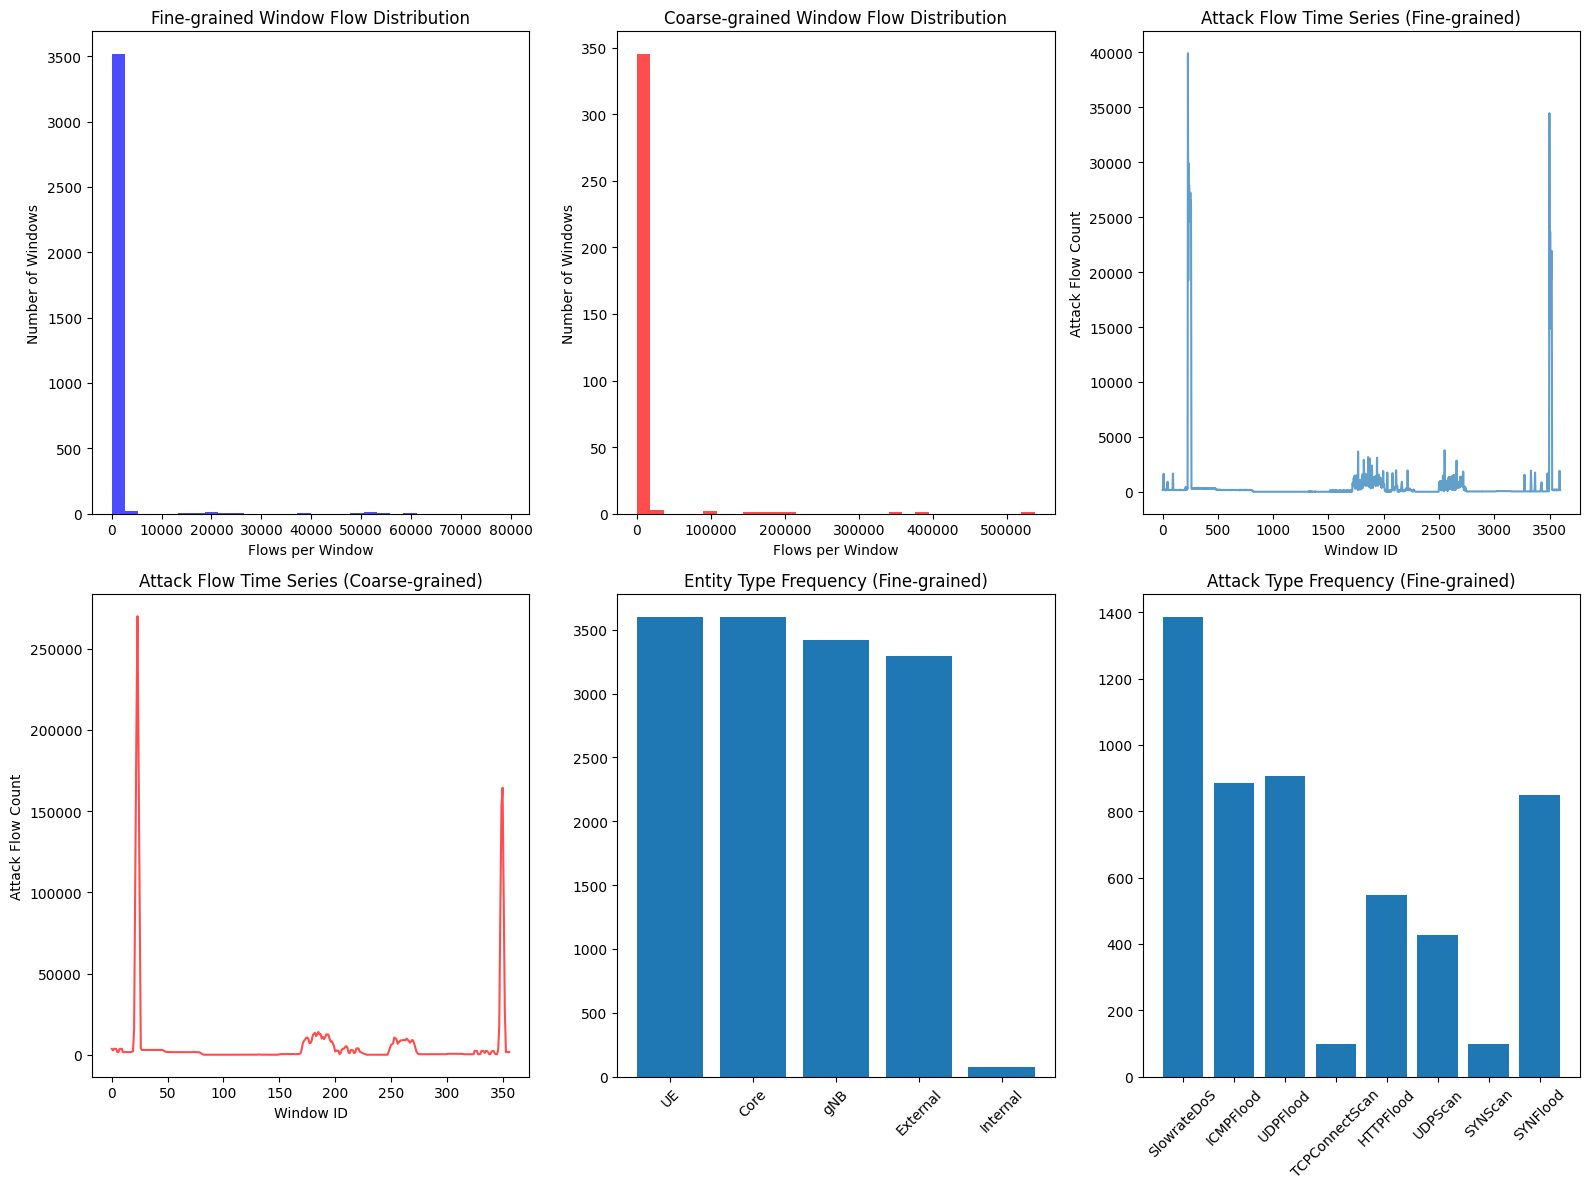

✓ JSON报告保存和验证成功
\n✓ Phase 4 完成:
  - 细粒度窗口: 3597 个文件
  - 粗粒度窗口: 357 个文件
  - 窗口报告: ../data/processed/metadata/windowing_report.json
  - 分析图表: ../data/processed/metadata/windowing_analysis.png


In [7]:
# 保存窗口数据
print("\\n保存时间窗口数据...")

# 创建窗口数据目录
fine_dir = '../data/processed/windowed_data/fine/'
coarse_dir = '../data/processed/windowed_data/coarse/'
os.makedirs(fine_dir, exist_ok=True)
os.makedirs(coarse_dir, exist_ok=True)

# 保存细粒度窗口数据
print(f"保存细粒度窗口数据...")
for i, window_data in enumerate(fine_windows):
    filename = f'fine_window_{i:04d}.pkl'
    window_data.to_csv(os.path.join(fine_dir, filename), index=False)

print(f"保存了 {len(fine_windows)} 个细粒度窗口文件")

# 保存粗粒度窗口数据
print(f"保存粗粒度窗口数据...")
for i, window_data in enumerate(coarse_windows):
    filename = f'coarse_window_{i:04d}.pkl'
    window_data.to_csv(os.path.join(coarse_dir, filename), index=False)

print(f"保存了 {len(coarse_windows)} 个粗粒度窗口文件")

# 统计分析
def analyze_windows(windows, window_type):
    """分析时间窗口统计信息"""
    if not windows:
        return {}
    
    window_sizes = [len(w) for w in windows]
    attack_counts = [len(w[w['Attack Type'] != 'Benign']) for w in windows]
    ue_flows = [len(w[w['SrcAddr_Type'] == 'UE']) for w in windows]
    
    stats = {
        'total_windows': len(windows),
        'avg_flows_per_window': np.mean(window_sizes),
        'min_flows_per_window': np.min(window_sizes),
        'max_flows_per_window': np.max(window_sizes),
        'std_flows_per_window': np.std(window_sizes),
        'avg_attacks_per_window': np.mean(attack_counts),
        'avg_ue_flows_per_window': np.mean(ue_flows),
        'empty_windows': sum(1 for size in window_sizes if size == 0),
        'non_empty_windows': sum(1 for size in window_sizes if size > 0)
    }
    
    return stats

# Numpy类型转换函数
def convert_numpy_types(obj):
    """递归转换numpy类型为Python原生类型"""
    if isinstance(obj, dict):
        return {key: convert_numpy_types(value) for key, value in obj.items()}
    elif isinstance(obj, list):
        return [convert_numpy_types(item) for item in obj]
    elif isinstance(obj, np.integer):
        return int(obj)
    elif isinstance(obj, np.floating):
        return float(obj)
    elif isinstance(obj, np.ndarray):
        return obj.tolist()
    else:
        return obj

# 分析窗口统计信息
fine_stats = analyze_windows(fine_windows, 'fine')
coarse_stats = analyze_windows(coarse_windows, 'coarse')

# 转换numpy类型为Python原生类型
fine_stats = convert_numpy_types(fine_stats)
coarse_stats = convert_numpy_types(coarse_stats)

print("\\n=== Fine-grained Window Statistics ===")
for key, value in fine_stats.items():
    print(f"{key}: {value:.2f}" if isinstance(value, float) else f"{key}: {value}")

print("\\n=== Coarse-grained Window Statistics ===")
for key, value in coarse_stats.items():
    print(f"{key}: {value:.2f}" if isinstance(value, float) else f"{key}: {value}")

# 可视化窗口分析
plt.figure(figsize=(16, 12))

# 1. 细粒度窗口流量分布
plt.subplot(2, 3, 1)
fine_sizes = [len(w) for w in fine_windows]
plt.hist(fine_sizes, bins=30, alpha=0.7, color='blue')
plt.title('Fine-grained Window Flow Distribution')
plt.xlabel('Flows per Window')
plt.ylabel('Number of Windows')

# 2. 粗粒度窗口流量分布  
plt.subplot(2, 3, 2)
coarse_sizes = [len(w) for w in coarse_windows]
plt.hist(coarse_sizes, bins=30, alpha=0.7, color='red')
plt.title('Coarse-grained Window Flow Distribution')
plt.xlabel('Flows per Window')
plt.ylabel('Number of Windows')

# 3. 攻击流量随时间变化(细粒度)
plt.subplot(2, 3, 3)
fine_attack_counts = [len(w[w['Attack Type'] != 'Benign']) for w in fine_windows]
plt.plot(fine_attack_counts, alpha=0.7)
plt.title('Attack Flow Time Series (Fine-grained)')
plt.xlabel('Window ID')
plt.ylabel('Attack Flow Count')

# 4. 攻击流量随时间变化(粗粒度)
plt.subplot(2, 3, 4)
coarse_attack_counts = [len(w[w['Attack Type'] != 'Benign']) for w in coarse_windows]
plt.plot(coarse_attack_counts, alpha=0.7, color='red')
plt.title('Attack Flow Time Series (Coarse-grained)')
plt.xlabel('Window ID')
plt.ylabel('Attack Flow Count')

# 5. 窗口内Entity Type Distribution(细粒度)
plt.subplot(2, 3, 5)
if fine_windows:
    entity_counts = defaultdict(int)
    for window in fine_windows:
        for entity_type in window['SrcAddr_Type'].value_counts().index:
            entity_counts[entity_type] += 1
    plt.bar(entity_counts.keys(), entity_counts.values())
    plt.title('Entity Type Frequency (Fine-grained)')
    plt.xticks(rotation=45)

# 6. 窗口内Attack Type Distribution
plt.subplot(2, 3, 6)
if fine_windows:
    attack_type_counts = defaultdict(int)
    for window in fine_windows:
        attacks = window[window['Attack Type'] != 'Benign']
        for attack_type in attacks['Attack Type'].value_counts().index:
            attack_type_counts[attack_type] += 1
    if attack_type_counts:
        plt.bar(range(len(attack_type_counts)), list(attack_type_counts.values()))
        plt.title('Attack Type Frequency (Fine-grained)')
        plt.xticks(range(len(attack_type_counts)), list(attack_type_counts.keys()), rotation=45)

plt.tight_layout()
plt.savefig('../data/processed/metadata/windowing_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

# 生成窗口分片报告
windowing_report = {
    "timestamp": datetime.now().isoformat(),
    "fine_window_config": {"window_size": 3, "step_size": 1},
    "coarse_window_config": {"window_size": 30, "step_size": 10},
    "fine_window_stats": fine_stats,
    "coarse_window_stats": coarse_stats,
    "total_processed_records": len(df),
    "files_saved": {
        "fine_windows": len(fine_windows),
        "coarse_windows": len(coarse_windows)
    },
    "storage_paths": {
        "fine_window_dir": fine_dir,
        "coarse_window_dir": coarse_dir
    }
}

# 保存JSON报告并添加错误处理
try:
    with open('../data/processed/metadata/windowing_report.json', 'w', encoding='utf-8') as f:
        json.dump(windowing_report, f, indent=2, ensure_ascii=False)
    
    # 验证JSON文件是否可以正确读取
    with open('../data/processed/metadata/windowing_report.json', 'r', encoding='utf-8') as f:
        test_data = json.load(f)
    print("✓ JSON报告保存和验证成功")
    
except (TypeError, ValueError) as e:
    print(f"✗ JSON序列化错误: {e}")
    print("数据类型检查:")
    for key, value in windowing_report.items():
        print(f"  {key}: {type(value)}")
except Exception as e:
    print(f"✗ 文件操作错误: {e}")

print("\\n✓ Phase 4 完成:")
print(f"  - 细粒度窗口: {len(fine_windows)} 个文件")
print(f"  - 粗粒度窗口: {len(coarse_windows)} 个文件")
print(f"  - 窗口报告: ../data/processed/metadata/windowing_report.json")
print(f"  - 分析图表: ../data/processed/metadata/windowing_analysis.png")


In [8]:
def create_dual_scale_windows(df):
    """
    双尺度时间窗实现：
    - 细粒度：3s窗口/1s步长（实时告警）
    - 粗粒度：30s窗口/10s步长（模式分析）
    """
    
    min_time = df['StartTime_unix'].min()
    max_time = df['StartTime_unix'].max()
    
    # 细粒度窗口
    fine_windows = []
    current_time = min_time
    while current_time < max_time:
        fine_windows.append({
            'start_time': current_time,
            'end_time': current_time + 3,
            'window_type': 'fine',
            'window_size': 3,
            'step_size': 1
        })
        current_time += 1
    
    # 粗粒度窗口
    coarse_windows = []
    current_time = min_time
    while current_time < max_time:
        coarse_windows.append({
            'start_time': current_time,
            'end_time': current_time + 30,
            'window_type': 'coarse',
            'window_size': 30,
            'step_size': 10
        })
        current_time += 10
    
    return fine_windows, coarse_windows

print("双尺度时间窗函数定义完成")


双尺度时间窗函数定义完成
